In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, mean_squared_error, r2_score,accuracy_score
from sklearn.datasets import load_diabetes

In [2]:
df=sns.load_dataset('titanic')
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [3]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB
None
survived         0
pclass           0
sex              0
age            177
si

In [4]:
df=df[['survived', 'pclass', 'age', 'sex', 'fare']].copy()
df=df.dropna()
df['sex']=df['sex'].map({'male': 0, 'female': 1})
print(df.head())

   survived  pclass   age  sex     fare
0         0       3  22.0    0   7.2500
1         1       1  38.0    1  71.2833
2         1       3  26.0    1   7.9250
3         1       1  35.0    1  53.1000
4         0       3  35.0    0   8.0500


In [5]:
X=df[['pclass', 'age', 'sex', 'fare']]
y=df['survived']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
lr=LogisticRegression()
lr.fit(X_train,y_train)
y_pred_lr=lr.predict(X_test)
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       0.81      0.78      0.80        87
           1       0.68      0.71      0.70        56

    accuracy                           0.76       143
   macro avg       0.74      0.75      0.75       143
weighted avg       0.76      0.76      0.76       143



In [7]:
dt=DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)
y_pred_dt=dt.predict(X_test)
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

           0       0.76      0.76      0.76        87
           1       0.62      0.62      0.62        56

    accuracy                           0.71       143
   macro avg       0.69      0.69      0.69       143
weighted avg       0.71      0.71      0.71       143



In [8]:
rf=RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.79      0.79      0.79        87
           1       0.68      0.68      0.68        56

    accuracy                           0.75       143
   macro avg       0.74      0.74      0.74       143
weighted avg       0.75      0.75      0.75       143



In [9]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,y_train)
y_pred_knn=knn.predict(X_test)
print(classification_report(y_test,y_pred_knn))

              precision    recall  f1-score   support

           0       0.70      0.77      0.73        87
           1       0.57      0.48      0.52        56

    accuracy                           0.66       143
   macro avg       0.64      0.63      0.63       143
weighted avg       0.65      0.66      0.65       143



In [10]:
results = pd.DataFrame({'Model': ['Logistic Regression', 'Decision Tree','Random Forest', 'KNN'],
                        'Accuracy':[lr.score(X_test, y_test),dt.score(X_test, y_test),rf.score(X_test, y_test),knn.score(X_test, y_test)]})
print(results.sort_values(by='Accuracy',ascending=False))

                 Model  Accuracy
0  Logistic Regression  0.755245
2        Random Forest  0.748252
1        Decision Tree  0.706294
3                  KNN  0.657343


In [11]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
X_reg = diabetes.data
y_reg = diabetes.target

In [12]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [13]:
reg = LinearRegression()
reg.fit(X_train_reg, y_train_reg)
y_pred_reg = reg.predict(X_test_reg)

In [14]:
print("Mean Squared Error:", mean_squared_error(y_test_reg, y_pred_reg))
print("R2 Score:", r2_score(y_test_reg, y_pred_reg))

Mean Squared Error: 2900.19362849348
R2 Score: 0.4526027629719197


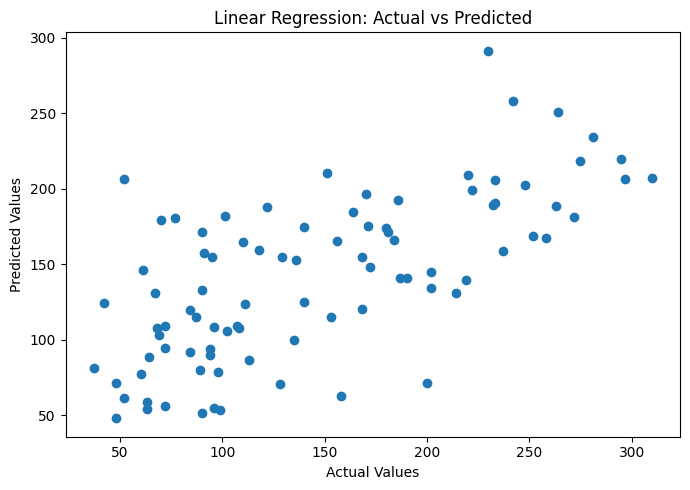

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, y_pred_reg)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Linear Regression: Actual vs Predicted')
plt.tight_layout()
plt.show()

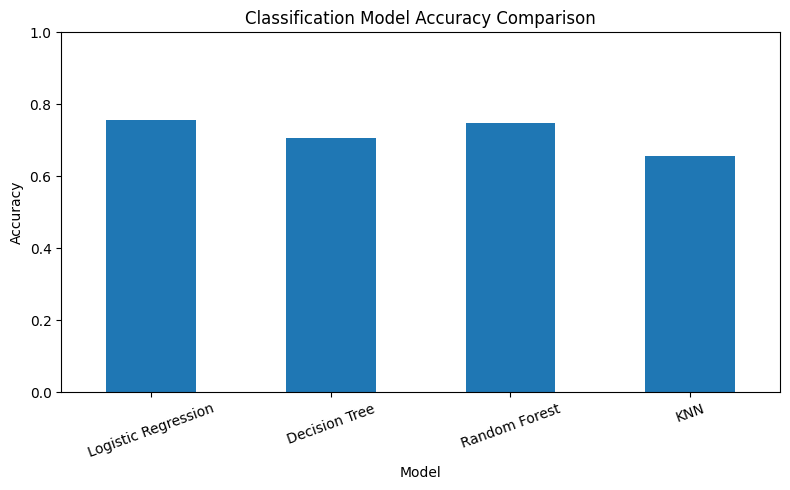

In [16]:
results.set_index('Model')['Accuracy'].plot(kind='bar',figsize=(8, 5))
plt.title('Classification Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()